# Entropy and cross entropy

Let's compute the entropy and cross entropy of letters in natural texts.

In [70]:
import numpy as np
import matplotlib.pyplot as plt
import requests
import os.path

filename = "Die_Leiden_des_jungen_Werther_.pdf"

filenames = ["werther.pdf","romeo_and_juilet.txt"]
urls = [
    "https://www.digbib.org/Johann_Wolfgang_von_Goethe_1749/Die_Leiden_des_jungen_Werther_.pdf",
    "https://flgr.sh/txtfssRomtxt?_ga=2.227974170.645047392.1795419057-901810997.1795419057"
]

for filename,url in zip(filenames,urls):
    if os.path.exists(filename):
        print("file "+filename+" already exists, skipping download")
    else:
        print("downloading..."+filename)
        with open(filename,"wb") as f:
            f.write(requests.get(url).content)

file werther.pdf already exists, skipping download
file romeo_and_juilet.txt already exists, skipping download


In [69]:
try:
    import pypdf
except:
    !pip install pypdf
    import pypdf

from pypdf import PdfReader

reader = PdfReader(filenames[0])
werther = "\n".join(page.extract_text() or "" for page in reader.pages)
with open(filenames[1]) as f:
    juliet = "".join([line for line in f])

print("** Werther by Goethe**")
print(werther[371:1000])
print("\n** Romeo and Juilet by Shakespear **")
print(juliet[300:580])

incorrect startxref pointer(3)


** Werther by Goethe**

Am 4. Mai 1771 
   Wie froh bin ich, daß ich weg bin!  Bester Freund, was ist das Herz des Menschen!  Dich zu
verlassen, den ich so liebe, von dem ich unzertrennlich war, und froh zu sein!  Ich weiß, du
verzeihst mir's. Waren nicht meine übrigen Verbindungen recht ausgesucht vom Schicksal, um ein
Herz wie das meine zu ängstigen?  Die arme Leonore!  Und doch war ich unschuldig.  Konnt' ich
dafür, daß, während die eigensinnigen Reize ihrer Schwester mir eine angenehme Unterhaltung
verschafften, daß eine Leidenschaft in dem armen Herzen sich bildete?  Und doch--bin ich ganz
unschuldig?  Hab' ich nicht ihre Empfindungen genä

** Romeo and Juilet by Shakespear **
ROMEO
MONTAGUE, his father
LADY MONTAGUE, his mother
BENVOLIO, their kinsman
ABRAM, a Montague servingman
BALTHASAR, Romeo's servingman
JULIET
CAPULET, her father
LADY CAPULET, her mother
NURSE to Juliet
TYBALT, kinsman to the Capulets
PETRUCHIO, Tybalt's companion


In [13]:
from collections import Counter
deutsch = Counter(text.lower())
english = Counter(juliet.lower())

abc="".join([chr(ord('a')+i) for i in range(26)])
frequencies_en = [english[c] for c in abc]
frequencies_de = [deutsch[c] for c in abc]


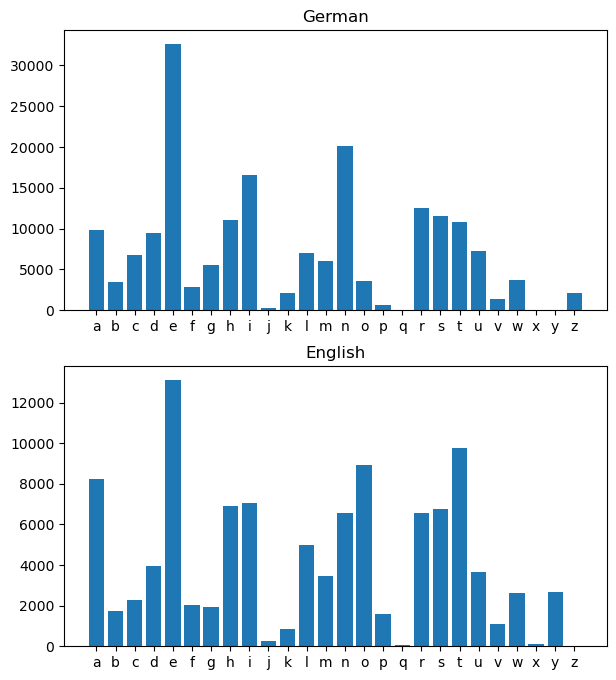

In [73]:

fig,axs = plt.subplots(2,1,figsize=(7,8))
axs[0].bar(range(26),frequencies_de)
axs[0].set_xticks(range(26), labels=abc)
axs[0].set_title("German")
axs[1].bar(range(26),frequencies_en)
axs[1].set_xticks(range(26), labels=abc)
axs[1].set_title("English")
pass

In [77]:
german = np.array(frequencies_de)/sum(frequencies_de)
english = np.array(frequencies_en)/sum(frequencies_en)

def entropy(p):
    return -(p*np.log(p,where=p>0)).sum()

print("entropy")
print(f"German     : {round(entropy(german),2)}")
print(f"English    : {round(entropy(english),2)}")
print(f"uniform    : {round(entropy(np.ones(26)/26),2)}")
print(f"unit vector: {round(entropy(np.array([1]+[0]*25)),2)}")

entropy
German     : 2.79
English    : 2.9
uniform    : 3.26
unit vector: -0.0


In [57]:
def xentropy(p,q):
    return -(p*np.log(q,where=p>0)).sum()

xentropy(german,german)

np.float64(2.793608171453895)

In [79]:
print(f"cross entropy(German, English): {round(xentropy(german,english),2)}")
print(f"cross entropy(English, German): {round(xentropy(english,german),2)}")
print(f"cross entropy(German, uniform): {round(xentropy(german,np.ones(26)/26),2)}")

cross entropy(German, English): 2.94
cross entropy(English, German): 3.14
cross entropy(German, uniform): 3.26
